# 01 — TCG vs Klioner (independent validation)
**What this notebook does:** Compares TEMPUS TCB−TCG against the independent TU Dresden (Klioner) Chebyshev solution over 200 years using the same INPOP19a ephemeris.

**Scope, deliberately narrow:** INPOP19a **TCB**, **planets only** (Sun + planet barycentres + Pluto, no asteroids). That is the configuration Klioner used and the one he compared against INPOP's own published series, so all three curves here describe the same physical model — any residual is method, not model. Other INPOP configurations (TDB vs TCB scaling, 19a vs 21a, asteroid perturbers) are deliberately out of scope and live in the INPOP-comparison notebook.

**Expected key result:** Detrended residuals TEMPUS − Klioner at the ns/cy level, confirming the O(c^-2) post-newtonian physics implementation is correct.

**Required data files:** `../data/ephem/inpop19a_TCB_m100_p100_tcg.dat`, `../data/time_ephem/tcx19a_TCG_m100_p100_asc_pos_TCB.asc`, `../data/time_ephem/inpop19a_TCB_m100_p100_asc_pos_TCG.asc`


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

from tempus import jd_split, jd_tt_to_tcb, TimeScalar
from tempus.chebycode import ChebySeries

from nb_utils import (
    DAY_S, JD_J2000,
    jd_to_et, et_to_jd, 
    jd_to_yr, yr_from_jd,
    plot_detrended_timescale,
    plot_compare_2timescales,
    run_tempus_integration,
)

## 1 · Run TEMPUS integration

Integrate TCG−TCB over ±100 years around J2000 using the INPOP19a TCB ephemeris.
The `--out-tcg-tcb` flag embeds the INPOP-internal TCG−TCB alongside the TEMPUS result,
providing an independent reference on the same time grid at no extra cost.

In [2]:
J2000_TT = 2451545.0  # J2000.0 in TT (Julian date)

eph_file = Path("../data/ephem/inpop19a_TCB_m100_p100_tcg.dat").resolve()
out_csv  = Path("../output/nb01_earth_m100_p100_INPOP19aTCB.csv").resolve()

# Anchor: J2000.0 TT -> TCB via the file's time ephemeris; span ±100 years (36525 days).
# All JD inputs are in the ephemeris-native timescale (TCB here), so the
# 0.75 d step is in TCB days. (--input-jd-are-tdb would switch inputs to TDB.)
s_int, s_frac = jd_tt_to_tcb(*jd_split(J2000_TT), eph_file)
start = TimeScalar(int(s_int) - 36525, s_frac)
end   = TimeScalar(int(s_int) + 36525, s_frac)

run_tempus_integration(
    eph_file=eph_file, out=out_csv, 
    start=start, end=end, jd_step=0.75,
    target='EARTH_CENTER',
    #ext='auto' resolves the Sun, all planets barycenters, and Plutos for the external potentials; 
    # consistent with what Klioner considered for external potentials
    ext='auto', 
    # --out_tcg_tcb: Validation aid, not typical usage: pulls INPOP's OWN published TCG-TCB 
    #  (embedded in the inpop29a_TCB*_tcg.dat release file), into a column beside the TEMPUS result
    out_tcg_tcb=True,
    zero=True,
);

Ephemeris version: INPOP19A
CALCEPH timescale: 2 (TCB)
  zeroed: TCB_minus_TCX = 0 at JD 2443144 + 0.5003725 (TCB) (shift -35.983421256289411 s)
Approx. mean drift (TCB-TCX): 1.279434 ms/day
Wrote /home/yan/PythonWorkdir/CNRS_Release/TEMPUS/output/nb01_earth_m100_p100_INPOP19aTCB.csv


## 2 · Load results

The CSV has five columns: `jd_int`, `jd_frac`, `SecondsPastJ2000` (similar to SPICE's `ET`, but here in TCB timescale rather than TDB, since we used a TCB ephemeris), `TCB−TCG` (TEMPUS), `TCG−TCB` (INPOP internal).  
Note the sign reversal: TEMPUS outputs TCB−TCG (positive drift), INPOP outputs TCG−TCB (negative drift).

In [ ]:
out_csv = Path("../output/nb01_earth_m100_p100_INPOP19aTCB.csv").resolve()

# Columns: jd_int, jd_frac, et [s], TCB−TCG [s] (TEMPUS), TCG−TCB [s] (INPOP)
jdi, jdf, et, TCB_minus_TCG_TEMPUS, TCG_minus_TCB_INPOP = np.genfromtxt(
    out_csv, delimiter=",", unpack=True, skip_header=1
)

# Align sign conventions 
TCG_TCB_TEMPUS = -TCB_minus_TCG_TEMPUS
TCG_TCB_INPOP  = TCG_minus_TCB_INPOP

## 3 · Klioner reference

Load the independent TU Dresden Chebyshev solution and the INPOP-published ASC file.
Both are evaluated at the same grid points as the TEMPUS output.

Source: <https://gaia.geo.tu-dresden.de/TimeEphemerides/>  
- `tcx19a_TCG_m100_p100_asc_pos_TCB.asc` — Klioner TCG−TCB derived from INPOP19a  
- `inpop19a_TCB_m100_p100_asc_pos_TCG.asc` — INPOP-native TCG−TCB as Chebyshev series

In [4]:
asc_klioner = ChebySeries.from_asc("../data/time_ephem/tcx19a_TCG_m100_p100_asc_pos_TCB.asc")
asc_inpop   = ChebySeries.from_asc("../data/time_ephem/inpop19a_TCB_m100_p100_asc_pos_TCG.asc")

# Evaluate at the exact split epochs from the CSV. Reconstructing the JD from
# et (et/86400 + J2000) rounds at ulp(2.45e6 d) ~ 4e-5 s and would inject a
# rate*delta_t argument error of ~1e-13 s into the ulp-level check below.
TCG_TCB_klioner   = asc_klioner.evaluate(jdi, jdf)
TCG_TCB_inpopfile = asc_inpop.evaluate(jdi, jdf)

jd_arr = jdi + jdf  # combined JD, for plot axes only

## 4 · Comparisons

First the three series together, then each one detrended (the secular drift removed, leaving the periodic signal), then the pairwise differences building confidence from inside out:
1. **TEMPUS − INPOP** — TEMPUS accuracy relative to the ephemeris that generated the reference values
2. **Klioner − INPOP** — confirms the independent solution is consistent with INPOP's own output
3. **TEMPUS − Klioner** — the key independent validation: two separate PN2 implementations, same ephemeris


### Overview

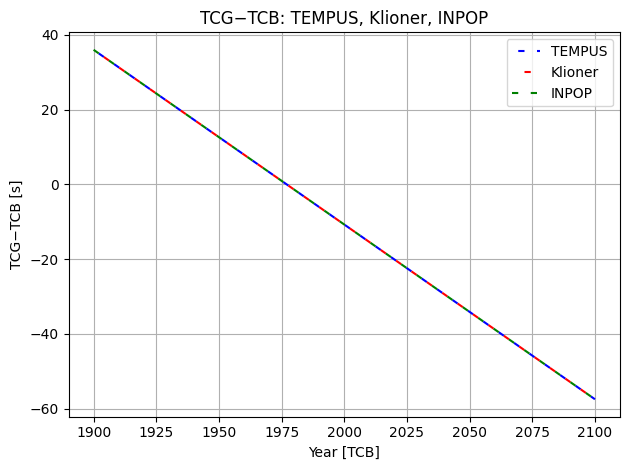

In [5]:
t_years = yr_from_jd(jd_arr)

#plt.figure(figsize=(13, 7))
plt.title("TCG−TCB: TEMPUS, Klioner, INPOP")
plt.plot(t_years, TCG_TCB_TEMPUS,  color="blue",  label="TEMPUS",  linestyle=(6, (3, 6)))
plt.plot(t_years, TCG_TCB_klioner, color="red",   label="Klioner", linestyle=(3, (3, 6)))
plt.plot(t_years, TCG_TCB_INPOP,   color="green", label="INPOP",   linestyle=(0, (3, 6)))
plt.ylabel("TCG−TCB [s]")
plt.xlabel("Year [TCB]")
plt.legend(loc="best")
plt.grid(True)
plt.tight_layout()
plt.savefig("../output/tcg200_directplot.pdf")
plt.show()

### Detrended series

If we detrend the TEMPUS and KLIONER Curves we get the following again similar looking curves:


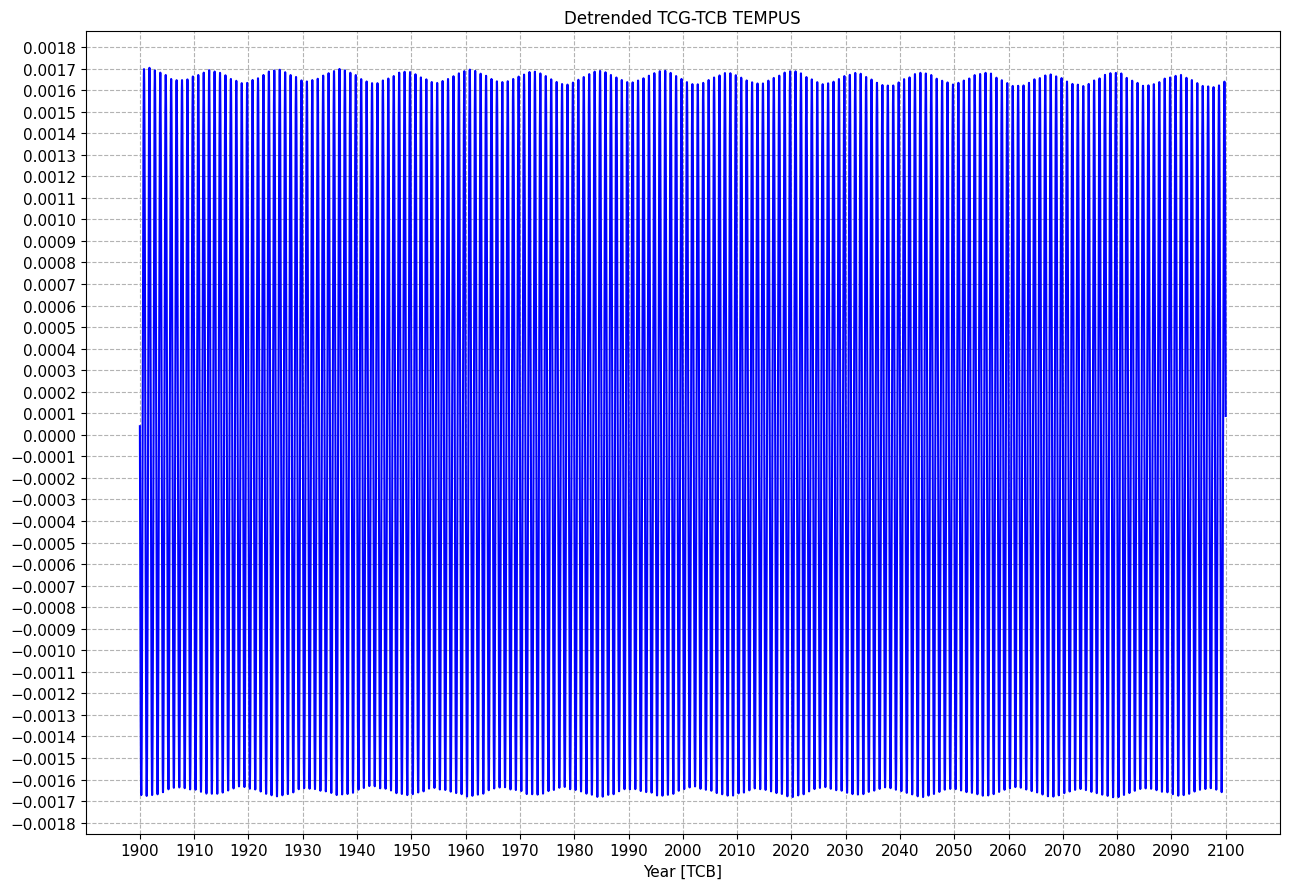

Linear fit slope (s/s): -1.480826605443883e-08
Linear fit slope (ms/day): -1.279434187103515
Min and Max of detrended TCG-TCB TEMPUS (ms): -1.6821112293428087 1.7034977520253847


In [6]:
plot_detrended_timescale(et, "Year [TCB]", TCG_TCB_TEMPUS, "TCG-TCB TEMPUS", "blue", x_tick=10, y_tick=1e-4)

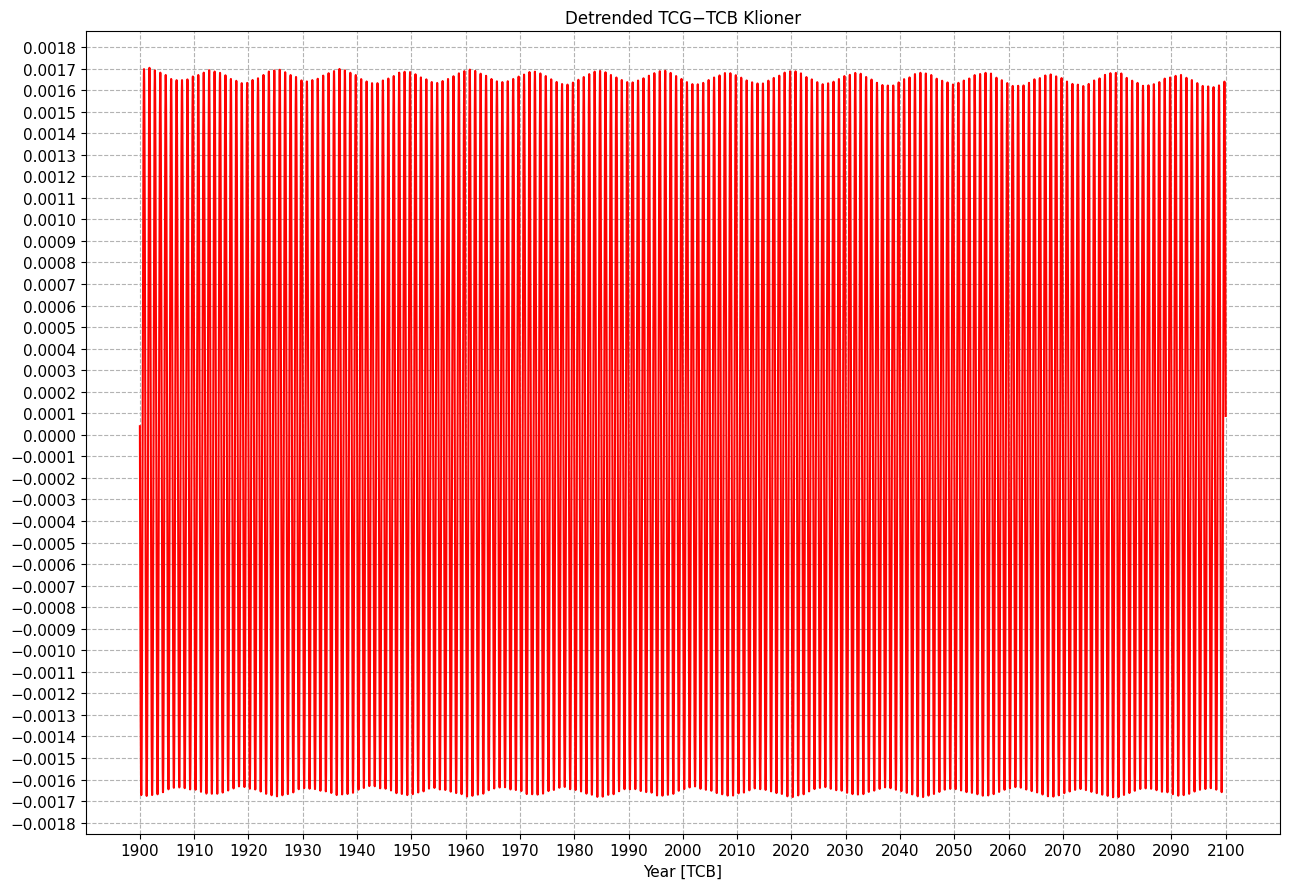

Linear fit slope (s/s): -1.4808266054434996e-08
Linear fit slope (ms/day): -1.2794341871031838
Min and Max of detrended TCG−TCB Klioner (ms): -1.6821112285754225 1.7034977510377303


In [7]:
plot_detrended_timescale(et, "Year [TCB]", TCG_TCB_klioner, "TCG−TCB Klioner", "red", x_tick=10, y_tick=1e-4)

These plots closely reproduce Klioners own: https://gaia.geo.tu-dresden.de/TimeEphemerides/TCXminusTCB/plots/deltaTCB-G.png

### TEMPUS minus INPOP

TEMPUS linear drift: -1.4808266054439e-08 s/s, -1.2794341871035295 ms/day
INPOP19a linear drift: -1.4808266060626572e-08 s/s, -1.2794341876381359 ms/day
Detrended INPOP19a min/max: -1.682e-03, 1.703e-03 s


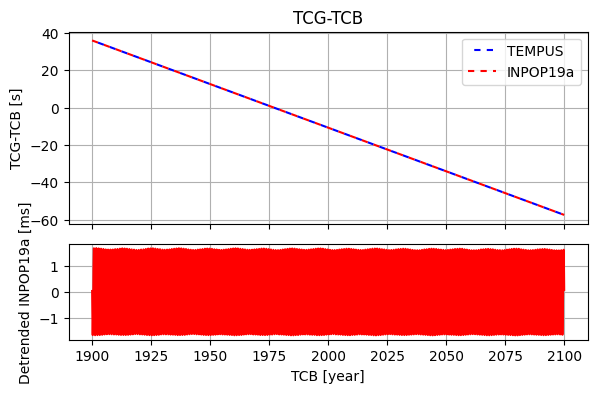

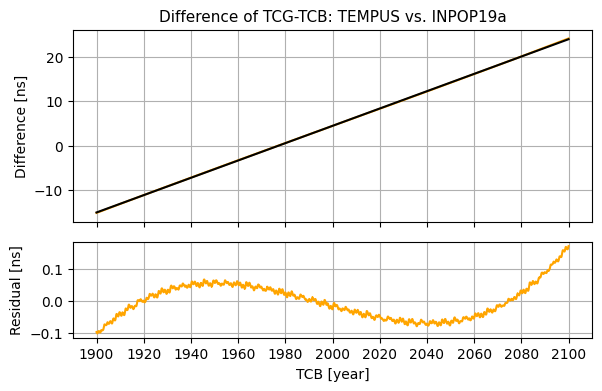

Drift slope (s/s): 6.1875468404658355e-18
Average drift per day (ps/day): 0.5346040470162482
Average drift per century (ns/cy): 19.526412817268465
Min and Max of detrended TCG-TCB (ns): -0.1017, 0.1727


In [8]:
plot_compare_2timescales(et, TCG_TCB_TEMPUS, "TEMPUS", TCG_TCB_INPOP, "INPOP19a", "TCG-TCB", #x_tick=10, overview=False,
                         x_tick=20, paper_mode=True, save_as="../output/tcg200_klionerlike_inpop.pdf")

### Klioner minus INPOP

1977 stitching jump removed: -5.365e-12 s (-5.36 ps)


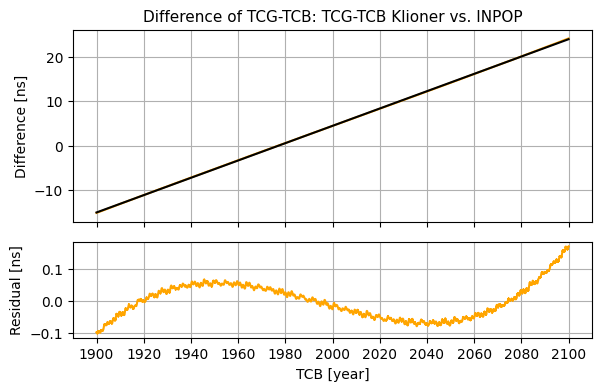

Drift slope (s/s): 6.192588431483908e-18
Average drift per day (ps/day): 0.5350396404802097
Average drift per century (ns/cy): 19.54232286853966
Min and Max of detrended TCG-TCB (ns): -0.1023, 0.1731


In [9]:
plot_compare_2timescales(et, TCG_TCB_klioner, "TCG-TCB Klioner", TCG_TCB_INPOP, "INPOP", "TCG-TCB", x_tick=20, overview=False,
                         fix_1977_jump=True, paper_mode=True,)

We reproduce a plot by Klioner that he shared with us in private communications, where he did the same comparison. Visually identical.

### TEMPUS minus Klioner (key result)

Two independent PN2 implementations on the same INPOP19a ephemeris.

Klioner linear drift: -1.4808266054435181e-08 s/s, -1.2794341871031996 ms/day
TEMPUS linear drift: -1.4808266054439e-08 s/s, -1.2794341871035295 ms/day
Detrended TEMPUS min/max: -1.682e-03, 1.703e-03 s


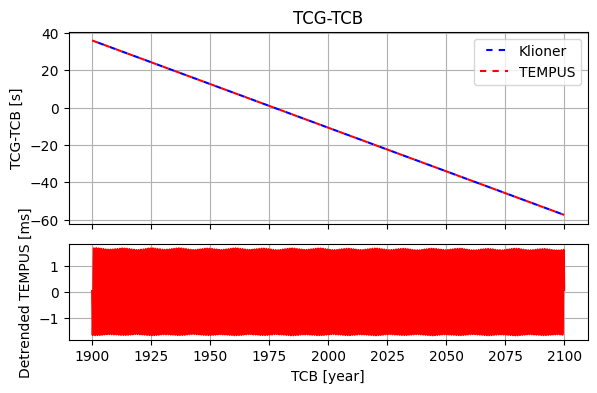

1977 stitching jump removed: -5.363e-12 s (-5.36 ps)


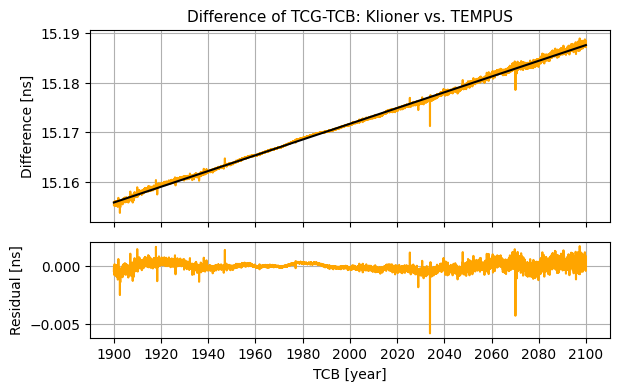

Drift slope (s/s): 5.041078973018446e-21
Average drift per day (ps/day): 0.0004355492232687937
Average drift per century (ns/cy): 0.015908435379892692
Min and Max of detrended TCG-TCB (ns): -0.0059, 0.0018


In [10]:
plot_compare_2timescales(et, TCG_TCB_klioner, "Klioner", TCG_TCB_TEMPUS-TCG_minus_TCB_INPOP[0]+TCG_TCB_klioner[0], 
                         "TEMPUS", "TCG-TCB", x_tick=20, paper_mode=True, fix_1977_jump=True,
                         save_as="../output/tcg200_klioner.pdf")